In [ ]:
pip install geopandas pyogrio shapely pandas openpyxl

In [ ]:
import zipfile
from pathlib import Path

arquivo_zip = Path("/pedo_area.zip")
pasta_destino = Path("/IBGE_Solos")

pasta_destino.mkdir(exist_ok=True)

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    zip_ref.extractall(pasta_destino)

print("Extração concluída!")

Extração concluída!


In [ ]:
from pathlib import Path

pasta = Path("/")

arquivo_roi = pasta / "/regiao_piloto.geojson"
pasta_solos = pasta / "/IBGE_Solos"
arquivo_saida = pasta / "Solos_Submedio_SF.gpkg"

shapefiles = list(pasta_solos.rglob("pedo_area*.shp"))

if not shapefiles:
    raise FileNotFoundError(
        "Nenhum shapefile pedológico encontrado."
    )

print("Shapefiles encontrados:")

for arquivo in shapefiles:
    print(arquivo)

Shapefiles encontrados:
/IBGE_Solos/pedo_area.shp


In [ ]:
print("GeoJSON encontrado:", arquivo_roi.exists())
print("Pasta de solos encontrada:", pasta_solos.exists())
print("Shapefiles encontrados:", len(shapefiles))

GeoJSON encontrado: True
Pasta de solos encontrada: True
Shapefiles encontrados: 1


In [ ]:
import geopandas as gpd
import pyogrio
from pathlib import Path

# 1. Definição dos arquivos
arquivo_roi = Path("/regiao_piloto.geojson")
arquivo_solos = Path("/IBGE_Solos/pedo_area.shp")
arquivo_saida = Path("/Solos_Submedio_SF.gpkg")

# 2. Carregamento da região piloto
roi = gpd.read_file(arquivo_roi)
roi["geometry"] = roi.geometry.make_valid()

# 3. Identificação da projeção dos solos
info = pyogrio.read_info(arquivo_solos)
crs_solos = info["crs"]

# Compatibilização das projeções
roi = roi.to_crs(crs_solos)

# 4. Carregamento otimizado dos solos
# Lê apenas os registros próximos à região piloto
solos = gpd.read_file(
    arquivo_solos,
    bbox=tuple(roi.total_bounds),
    engine="pyogrio"
)

solos["geometry"] = solos.geometry.make_valid()

print("Unidades pedológicas carregadas:", len(solos))

# 5. Recorte exato da região piloto
solos_recortados = gpd.clip(
    solos,
    roi,
    keep_geom_type=True
)

# Conversão para WGS 84
solos_recortados = solos_recortados.to_crs("EPSG:4326")

# 6. Exportação
solos_recortados.to_file(
    arquivo_saida,
    layer="solos",
    driver="GPKG",
    index=False
)

# 7. Verificação dos resultados
print("\nUnidades pedológicas após o recorte:")
print(len(solos_recortados))

print("\nColunas disponíveis:")
print(solos_recortados.columns.tolist())

print("\nPrimeiros registros:")
display(solos_recortados.head())

print("\nArquivo gerado:", arquivo_saida)

Unidades pedológicas carregadas: 537

Unidades pedológicas após o recorte:
261

Colunas disponíveis:
['id1', 'cd_fcim', 'nom_unidad', 'cod_simbol', 'val_ncompo', 'legenda', 'ordem', 'subordem', 'grande_gru', 'subgrupos', 'textura', 'horizonte', 'erosao', 'pedregosid', 'rochosidad', 'relevo', 'componente', 'component1', 'component2', 'component3', 'inclu_p1', 'inclu_p2', 'inclu_p3', 'ar_poli_km', 'leg_ordem', 'legenda_2', 'cd_ord_id', 'cd_leg2_id', 'geometry']

Primeiros registros:


,id1,cd_fcim,nom_unidad,cod_simbol,val_ncompo,legenda,ordem,subordem,grande_gru,subgrupos,...,component3,inclu_p1,inclu_p2,inclu_p3,ar_poli_km,leg_ordem,legenda_2,cd_ord_id,cd_leg2_id,geometry
282,58899,SC24,RLe15,RLe,4.0,RLe - Neossolo Litólico Eutrófico,NEOSSOLO,LITÓLICO,Eutrófico,típico,...,None,I AFLORAMENTOS DE ROCHAS + I CAMBISSOLO HÁPLIC...,None,None,39.5608,NEOSSOLO,NEOSSOLO LITÓLICO,8.0,28.0,"POLYGON ((-40.41606 -9.89949, -40.41578 -9.899..."
89,58881,SC24,CXve4,CXve,6.0,CXve - Cambissolo Háplico Ta Eutrófico,CAMBISSOLO,HÁPLICO,Ta Eutrófico,típico e léptico,...,None,I LUVISSOLO CRÔMICO Órtico típico média/argilo...,LATOSSOLO VERMELHO-AMARELO Distrófico típico m...,None,234.8231,CAMBISSOLO,CAMBISSOLO HÁPLICO,2.0,7.0,"MULTIPOLYGON (((-40.31586 -9.89227, -40.31736 ..."
77,58898,SC24,CXk3,CXk,6.0,CXk - Cambissolo Háplico Carbonático,CAMBISSOLO,HÁPLICO,Carbonático,léptico,...,None,I LATOSSOLO VERMELHO Eutrófico típico média e ...,None,None,7.4183,CAMBISSOLO,CAMBISSOLO HÁPLICO,2.0,7.0,"POLYGON ((-40.69061 -9.84311, -40.68709 -9.843..."
88,59364,SC24,CXve4,CXve,6.0,CXve - Cambissolo Háplico Ta Eutrófico,CAMBISSOLO,HÁPLICO,Ta Eutrófico,típico e léptico,...,None,I LUVISSOLO CRÔMICO Órtico típico média/argilo...,LATOSSOLO VERMELHO-AMARELO Distrófico típico m...,None,90.1428,CAMBISSOLO,CAMBISSOLO HÁPLICO,2.0,7.0,"POLYGON ((-40.58367 -9.70883, -40.58272 -9.709..."
86,59394,SC24,CXk12,CXk,6.0,CXk - Cambissolo Háplico Carbonático,CAMBISSOLO,HÁPLICO,Carbonático,típico,...,None,I LATOSSOLO VERMELHO-AMARELO Distrófico típico...,None,None,56.8344,CAMBISSOLO,CAMBISSOLO HÁPLICO,2.0,7.0,"POLYGON ((-40.50822 -9.72698, -40.50862 -9.726..."



Arquivo gerado: /Solos_Submedio_SF.gpkg


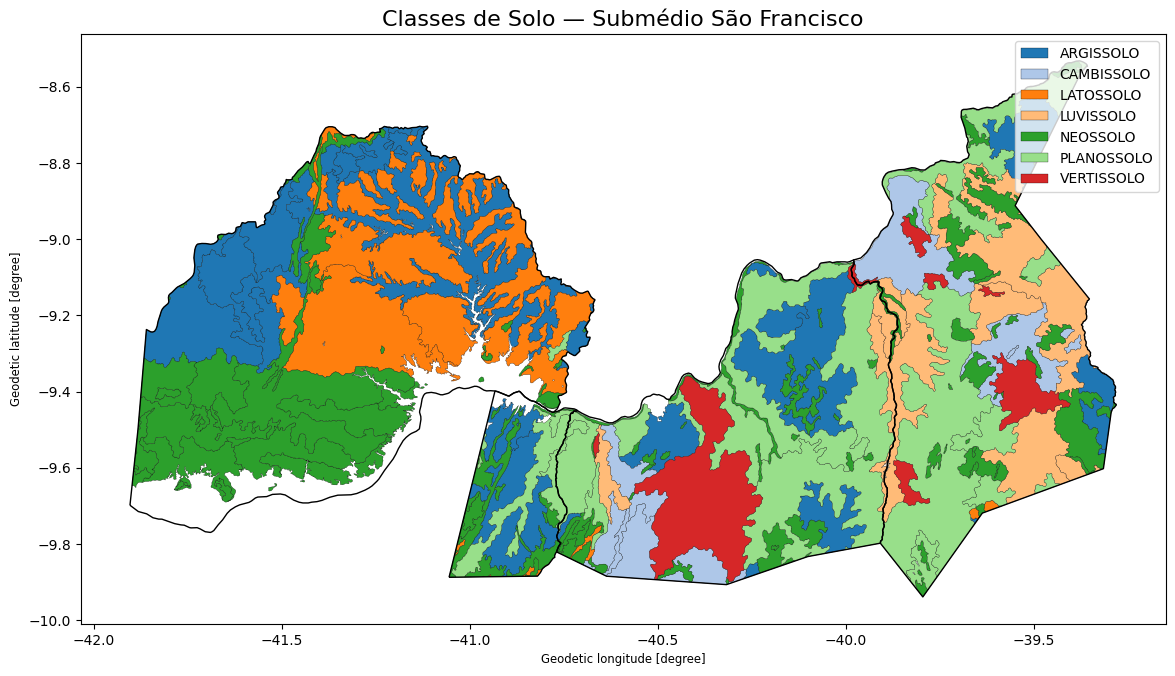

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 10))

solos_recortados.plot(
    ax=ax,
    column="ordem",
    categorical=True,
    legend=True,
    cmap="tab20",
    edgecolor="black",
    linewidth=0.2
)

roi.to_crs("EPSG:4326").boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

ax.set_title(
    "Classes de Solo — Submédio São Francisco",
    fontsize=16
)

plt.show()

In [ ]:
from google.colab import files

files.download("/Solos_Submedio_SF.gpkg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import geopandas as gpd

solos = gpd.read_file("/Solos_Submedio_SF.gpkg")

print("Quantidade de unidades pedológicas:", len(solos))
print("Sistema de coordenadas:", solos.crs)
print("Geometrias inválidas:", (~solos.geometry.is_valid).sum())

print("\nColunas disponíveis:")
print(solos.columns.tolist())

print("\nClasses de solo:")
print(solos["ordem"].value_counts(dropna=False))

print("\nSubclasses de solo:")
print(solos["subordem"].value_counts(dropna=False))

print("\nClasses texturais:")
print(solos["textura"].value_counts(dropna=False))

Quantidade de unidades pedológicas: 261
Sistema de coordenadas: EPSG:4326
Geometrias inválidas: 0

Colunas disponíveis:
['id1', 'cd_fcim', 'nom_unidad', 'cod_simbol', 'val_ncompo', 'legenda', 'ordem', 'subordem', 'grande_gru', 'subgrupos', 'textura', 'horizonte', 'erosao', 'pedregosid', 'rochosidad', 'relevo', 'componente', 'component1', 'component2', 'component3', 'inclu_p1', 'inclu_p2', 'inclu_p3', 'ar_poli_km', 'leg_ordem', 'legenda_2', 'cd_ord_id', 'cd_leg2_id', 'geometry']

Classes de solo:
ordem
NEOSSOLO      129
ARGISSOLO      34
LATOSSOLO      29
None           20
PLANOSSOLO     18
CAMBISSOLO     12
LUVISSOLO      11
VERTISSOLO      8
Name: count, dtype: int64

Subclasses de solo:
subordem
LITÓLICO            95
HÁPLICO             38
AMARELO             32
VERMELHO-AMARELO    31
None                20
QUARTZARÊNICO       16
FLÚVICO             15
CRÔMICO             11
REGOLÍTICO           3
Name: count, dtype: int64

Classes texturais:
textura
arenosa e média                 

In [ ]:
import geopandas as gpd

solos = gpd.read_file("/Solos_Submedio_SF.gpkg")

# Padronização das categorias
ordem = solos["ordem"].astype("string").str.strip().str.upper()
subordem = solos["subordem"].astype("string").str.strip().str.upper()

# Criação da feature categórica
solos["classe_solo"] = ordem

# Preservação das subclasses dos Neossolos
mask = ordem.eq("NEOSSOLO").fillna(False)

solos.loc[mask, "classe_solo"] = (
    ordem[mask] + " " + subordem[mask]
)

print("Classes de solo para o KNN:")
print(solos["classe_solo"].value_counts(dropna=False))

# Exportação da base preparada
solos.to_file(
    "/Solos_Submedio_SF_KNN.gpkg",
    layer="solos",
    driver="GPKG",
    index=False
)

Classes de solo para o KNN:
classe_solo
NEOSSOLO LITÓLICO         95
ARGISSOLO                 34
LATOSSOLO                 29
<NA>                      20
PLANOSSOLO                18
NEOSSOLO QUARTZARÊNICO    16
NEOSSOLO FLÚVICO          15
CAMBISSOLO                12
LUVISSOLO                 11
VERTISSOLO                 8
NEOSSOLO REGOLÍTICO        3
Name: count, dtype: Int64


In [ ]:
from google.colab import files

files.download("/Solos_Submedio_SF_KNN.gpkg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd

# ==========================================================
# BASE SINTÉTICA DE REFERÊNCIA AGROFLORESTAL
# Exclusivamente para prova de conceito (PoC)
# ==========================================================

dados = [

    # SISTEMA SILVIPASTORIL (IPF)

    ["IPF01", 0.30, 0.34, 0.05, -0.015, "LUVISSOLO", "IPF"],
    ["IPF02", 0.35, 0.38, 0.06, -0.012, "ARGISSOLO", "IPF"],
    ["IPF03", 0.28, 0.32, 0.04, -0.018, "NEOSSOLO LITÓLICO", "IPF"],
    ["IPF04", 0.33, 0.36, 0.05, -0.010, "CAMBISSOLO", "IPF"],

    # SISTEMA AGROSSILVIPASTORIL (ILPF)

    ["ILPF01", 0.40, 0.43, 0.05, -0.008, "LUVISSOLO", "ILPF"],
    ["ILPF02", 0.42, 0.45, 0.04, -0.010, "LATOSSOLO", "ILPF"],
    ["ILPF03", 0.38, 0.41, 0.06, -0.012, "ARGISSOLO", "ILPF"],
    ["ILPF04", 0.36, 0.40, 0.05, -0.015, "VERTISSOLO", "ILPF"],

    # REGENERAÇÃO NATURAL ASSISTIDA (RNA)

    ["RNA01", 0.19, 0.27, 0.08, -0.035, "NEOSSOLO LITÓLICO", "RNA"],
    ["RNA02", 0.21, 0.29, 0.09, -0.030, "NEOSSOLO QUARTZARÊNICO", "RNA"],
    ["RNA03", 0.23, 0.30, 0.07, -0.028, "PLANOSSOLO", "RNA"],
    ["RNA04", 0.25, 0.33, 0.08, -0.025, "CAMBISSOLO", "RNA"]

]

colunas = [
    "id_caso",
    "ndvi_2025",
    "ndvi_media_historica",
    "ndvi_std_historico",
    "ndvi_tendencia",
    "classe_solo",
    "solucao"
]

casos = pd.DataFrame(dados, columns=colunas)

# Identificação explícita da natureza dos dados
casos["tipo_dado"] = "SINTETICO"

nomes = {
    "IPF": "Sistema Silvipastoril",
    "ILPF": "Sistema Agrossilvipastoril",
    "RNA": "Regeneração Natural Assistida"
}

casos["nome_solucao"] = casos["solucao"].map(nomes)

# Exportação
casos.to_csv(
    "/Casos_Referencia_Simulados.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dimensões:", casos.shape)

print("\nDistribuição das soluções:")
print(casos["solucao"].value_counts())

print("\nValores ausentes:", casos.isna().sum().sum())

display(casos)

print("\nArquivo exportado com sucesso!")


Dimensões: (12, 9)

Distribuição das soluções:
solucao
IPF     4
ILPF    4
RNA     4
Name: count, dtype: int64

Valores ausentes: 0


,id_caso,ndvi_2025,ndvi_media_historica,ndvi_std_historico,ndvi_tendencia,classe_solo,solucao,tipo_dado,nome_solucao
0,IPF01,0.30,0.34,0.05,-0.015,LUVISSOLO,IPF,SINTETICO,Sistema Silvipastoril
1,IPF02,0.35,0.38,0.06,-0.012,ARGISSOLO,IPF,SINTETICO,Sistema Silvipastoril
2,IPF03,0.28,0.32,0.04,-0.018,NEOSSOLO LITÓLICO,IPF,SINTETICO,Sistema Silvipastoril
3,IPF04,0.33,0.36,0.05,-0.010,CAMBISSOLO,IPF,SINTETICO,Sistema Silvipastoril
4,ILPF01,0.40,0.43,0.05,-0.008,LUVISSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
5,ILPF02,0.42,0.45,0.04,-0.010,LATOSSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
6,ILPF03,0.38,0.41,0.06,-0.012,ARGISSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
7,ILPF04,0.36,0.40,0.05,-0.015,VERTISSOLO,ILPF,SINTETICO,Sistema Agrossilvipastoril
8,RNA01,0.19,0.27,0.08,-0.035,NEOSSOLO LITÓLICO,RNA,SINTETICO,Regeneração Natural Assistida
9,RNA02,0.21,0.29,0.09,-0.030,NEOSSOLO QUARTZARÊNICO,RNA,SINTETICO,Regeneração Natural Assistida



Arquivo exportado com sucesso!


In [ ]:
from google.colab import files

files.download("/Casos_Referencia_Simulados.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>